In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('titanic.csv')
print(df.shape)
df.head()

(891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
print(df.isna().sum()[df.isna().sum() > 0])
print()
print(df['Survived'].value_counts(normalize=True).round(3))

Age         177
Cabin       687
Embarked      2
dtype: int64

Survived
0    0.616
1    0.384
Name: proportion, dtype: float64


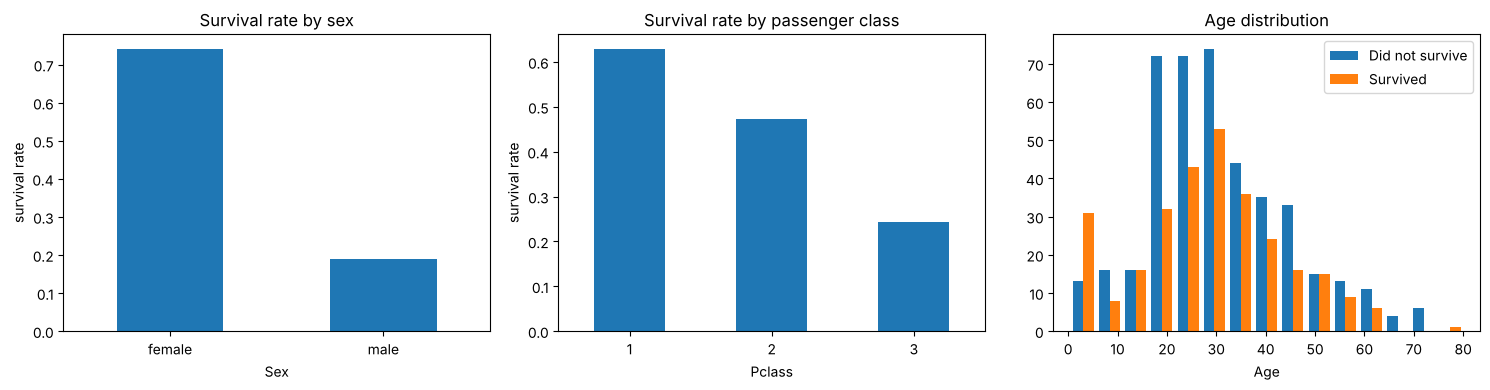

In [4]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))

df.groupby('Sex')['Survived'].mean().plot.bar(ax=ax[0], rot=0)
ax[0].set_title('Survival rate by sex'); ax[0].set_ylabel('survival rate')

df.groupby('Pclass')['Survived'].mean().plot.bar(ax=ax[1], rot=0)
ax[1].set_title('Survival rate by passenger class'); ax[1].set_ylabel('survival rate')

ax[2].hist([df[df.Survived == 0]['Age'].dropna(), df[df.Survived == 1]['Age'].dropna()],
           bins=15, label=['Did not survive', 'Survived'])
ax[2].set_title('Age distribution'); ax[2].set_xlabel('Age'); ax[2].legend()
plt.tight_layout()
plt.show()

In [5]:
np.random.seed(42)

train_idx, test_idx = [], []
for cls in [0, 1]:
    idx = np.where(df['Survived'].values == cls)[0]
    idx = np.random.permutation(idx)
    n_test = int(0.2 * len(idx))
    test_idx.extend(idx[:n_test])
    train_idx.extend(idx[n_test:])

train_df = df.iloc[np.random.permutation(train_idx)].reset_index(drop=True)
test_df  = df.iloc[np.random.permutation(test_idx)].reset_index(drop=True)

print('Training set:', train_df.shape, ' survival rate:', round(train_df['Survived'].mean(), 3))
print('Testing set :', test_df.shape,  ' survival rate:', round(test_df['Survived'].mean(), 3))

Training set: (714, 12)  survival rate: 0.384
Testing set : (177, 12)  survival rate: 0.384


In [6]:
age_median    = train_df['Age'].median()
embarked_mode = train_df['Embarked'].mode()[0]

def preprocess(data):
    out = pd.DataFrame()
    out['Pclass']     = data['Pclass']
    out['Sex']        = (data['Sex'] == 'female').astype(int)
    out['Age']        = data['Age'].fillna(age_median)
    out['SibSp']      = data['SibSp']
    out['Parch']      = data['Parch']
    out['Fare']       = data['Fare']
    emb               = data['Embarked'].fillna(embarked_mode)
    out['Embarked_Q'] = (emb == 'Q').astype(int)
    out['Embarked_S'] = (emb == 'S').astype(int)
    return out

X_train_df, X_test_df = preprocess(train_df), preprocess(test_df)
feature_names = list(X_train_df.columns)

X_train = X_train_df.values.astype(float)
X_test  = X_test_df.values.astype(float)
y_train = train_df['Survived'].values
y_test  = test_df['Survived'].values

# Standardization with training statistics only
mean, std = X_train.mean(axis=0), X_train.std(axis=0)
X_train = (X_train - mean) / std
X_test  = (X_test  - mean) / std

print('Features:', feature_names)
print('Missing values left:', X_train_df.isna().sum().sum() + X_test_df.isna().sum().sum())

Features: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_S']
Missing values left: 0


In [7]:
class LogisticRegressionScratch:
    def __init__(self, learning_rate=0.1, n_iterations=2000, threshold=0.5):
        self.learning_rate = learning_rate
        self.n_iterations = n_iterations
        self.threshold = threshold
        self.weights = None
        self.bias = 0.0
        self.loss_history = []

    def _sigmoid(self, z):
        z = np.clip(z, -500, 500)               # avoid overflow in exp
        return 1 / (1 + np.exp(-z))

    def _loss(self, y, p):
        eps = 1e-15                              # avoid log(0)
        p = np.clip(p, eps, 1 - eps)
        return -np.mean(y * np.log(p) + (1 - y) * np.log(1 - p))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.weights = np.zeros(n_features)
        self.bias = 0.0
        self.loss_history = []

        for i in range(self.n_iterations):
            p = self._sigmoid(np.dot(X, self.weights) + self.bias)

            dw = np.dot(X.T, (p - y)) / n_samples
            db = np.mean(p - y)

            self.weights -= self.learning_rate * dw
            self.bias    -= self.learning_rate * db

            self.loss_history.append(self._loss(y, p))
            if i % 500 == 0:
                print("iter={:d}    loss={:.4f}".format(i, self.loss_history[-1]))
        return self

    def predict_proba(self, X):
        return self._sigmoid(np.dot(X, self.weights) + self.bias)

    def predict(self, X):
        return (self.predict_proba(X) >= self.threshold).astype(int)

In [8]:
model = LogisticRegressionScratch(learning_rate=0.1, n_iterations=2000)
model.fit(X_train, y_train)

iter=0    loss=0.6931
iter=500    loss=0.4360
iter=1000    loss=0.4358
iter=1500    loss=0.4358


In [9]:
train_pred = model.predict(X_train)
test_pred  = model.predict(X_test)
test_prob  = model.predict_proba(X_test)

results = pd.DataFrame({'Actual': y_test, 'Predicted': test_pred, 'P(survived)': test_prob.round(3)})
results.head(10)

,Actual,Predicted,P(survived)
0,0,0,0.128
1,0,0,0.096
2,0,0,0.134
3,0,0,0.241
4,0,1,0.613
5,0,0,0.383
6,0,0,0.206
7,1,1,0.644
8,1,1,0.799
9,0,0,0.078


In [10]:
def confusion_matrix(y, p):
    tn = np.sum((y == 0) & (p == 0)); fp = np.sum((y == 0) & (p == 1))
    fn = np.sum((y == 1) & (p == 0)); tp = np.sum((y == 1) & (p == 1))
    return np.array([[tn, fp], [fn, tp]])

def accuracy(y, p):  return np.mean(y == p)
def precision(y, p):
    tp = np.sum((y == 1) & (p == 1)); fp = np.sum((y == 0) & (p == 1))
    return tp / (tp + fp) if tp + fp > 0 else 0.0
def recall(y, p):
    tp = np.sum((y == 1) & (p == 1)); fn = np.sum((y == 1) & (p == 0))
    return tp / (tp + fn) if tp + fn > 0 else 0.0
def f1_score(y, p):
    pr, rc = precision(y, p), recall(y, p)
    return 2 * pr * rc / (pr + rc) if pr + rc > 0 else 0.0
def log_loss(y, prob):
    prob = np.clip(prob, 1e-15, 1 - 1e-15)
    return -np.mean(y * np.log(prob) + (1 - y) * np.log(1 - prob))

def roc_curve(y, prob):
    order = np.argsort(-prob)                    # highest probability first
    y_sorted = y[order]
    tpr = np.concatenate([[0], np.cumsum(y_sorted) / y.sum()])
    fpr = np.concatenate([[0], np.cumsum(1 - y_sorted) / (1 - y).sum()])
    return fpr, tpr

def auc_score(fpr, tpr):
    return np.sum((fpr[1:] - fpr[:-1]) * (tpr[1:] + tpr[:-1]) / 2)   # trapezoid rule

train_prob = model.predict_proba(X_train)
fpr, tpr = roc_curve(y_test, test_prob)

metrics = pd.DataFrame({
    'Training': [accuracy(y_train, train_pred), precision(y_train, train_pred), recall(y_train, train_pred),
                 f1_score(y_train, train_pred), auc_score(*roc_curve(y_train, train_prob)), log_loss(y_train, train_prob)],
    'Testing':  [accuracy(y_test, test_pred), precision(y_test, test_pred), recall(y_test, test_pred),
                 f1_score(y_test, test_pred), auc_score(fpr, tpr), log_loss(y_test, test_prob)]
}, index=['Accuracy', 'Precision', 'Recall', 'F1-score', 'ROC-AUC', 'Log loss'])

print('Baseline accuracy (always predict "did not survive"):', round(np.mean(y_test == 0), 3))
metrics.round(3)

Baseline accuracy (always predict "did not survive"): 0.616


,Training,Testing
Accuracy,0.804,0.780
Precision,0.764,0.716
Recall,0.708,0.706
F1-score,0.735,0.711
ROC-AUC,0.861,0.839
Log loss,0.436,0.468


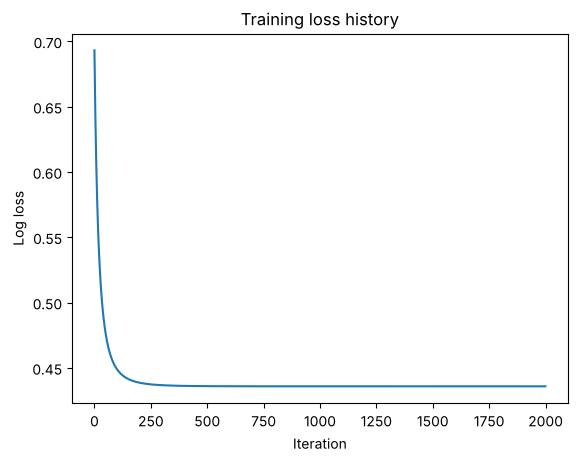

In [11]:
plt.plot(model.loss_history)
plt.xlabel('Iteration'); plt.ylabel('Log loss')
plt.title('Training loss history')
plt.show()

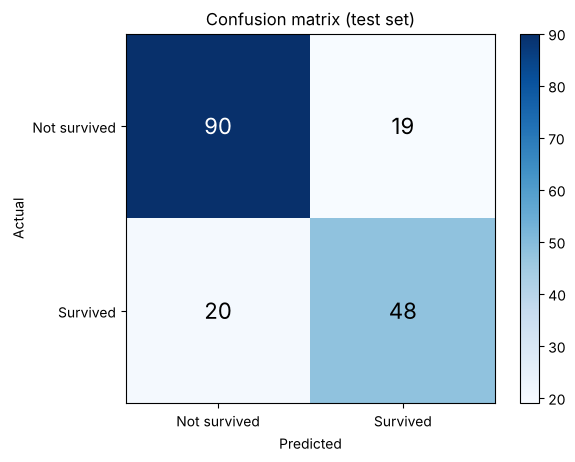

In [12]:
cm = confusion_matrix(y_test, test_pred)

plt.imshow(cm, cmap='Blues')
for i in range(2):
    for j in range(2):
        plt.text(j, i, cm[i, j], ha='center', va='center', fontsize=16,
                 color='white' if cm[i, j] > 0.6 * cm.max() else 'black')
plt.xticks([0, 1], ['Not survived', 'Survived']); plt.yticks([0, 1], ['Not survived', 'Survived'])
plt.xlabel('Predicted'); plt.ylabel('Actual'); plt.title('Confusion matrix (test set)')
plt.colorbar()
plt.show()

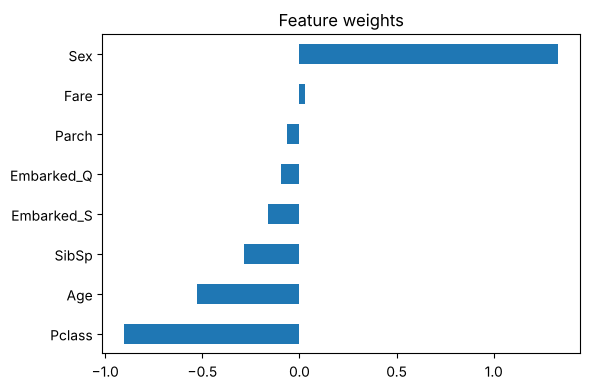

Bias (intercept): -0.636


In [15]:
pd.Series(model.weights, index=feature_names).sort_values().plot.barh(figsize=(6, 4), title='Feature weights')
plt.tight_layout()
plt.show()
print('Bias (intercept):', round(model.bias, 3))